# Duka Electronics | H1 2026 Board Report

## Storyboard — before any plotting

**Audience:** Duka Electronics board members and CEO. They are non-technical, time-poor, and will read this report on a phone before the meeting.

**Decision they own:** Where to focus commercial attention and resources in the second half of 2026.

**Big Idea:** H1 revenue is concentrated in Nairobi and higher-priced Laptops, while monthly revenue peaked in April and finished lower in June. Protect the leading revenue engines while testing focused actions to rebuild momentum.

**SCR (Situation–Complication–Resolution):**
1. **Situation:** Duka recorded 1,000 orders and KES 71.8M in sales revenue from January through June 2026.
2. **Complication:** Revenue is concentrated in Nairobi and Laptops, and June was the lowest-revenue month after April's peak; unit volume alone does not explain value.
3. **Resolution:** Protect availability and customer experience for Nairobi and Laptop sales, then test targeted demand-building in other branches and monitor monthly revenue before scaling.

**Measures and scope:** Revenue is quantity multiplied by listed unit price; it is sales value, not profit. The source contains order-level records dated 1 January–29 June 2026. All recommendations are directional because the data has no costs, inventory, customer, or marketing fields.

## Prepare and validate the H1 measures

Load the supplied order-level data, calculate revenue, and derive the summaries used by every chart. The checks make the report reproducible from the included CSV.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = Path('duka_sales.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('..') / 'duka_sales.csv'
sales = pd.read_csv(DATA_PATH, parse_dates=['order_date'])
sales['revenue'] = sales['quantity'] * sales['unit_price']

assert sales['order_id'].is_unique, 'Expected one row per unique order.'
assert sales[['order_date', 'branch', 'product', 'quantity', 'unit_price']].notna().all().all()
assert sales['order_date'].between('2026-01-01', '2026-06-30').all()

monthly = sales.groupby(pd.Grouper(key='order_date', freq='MS'))['revenue'].sum()
branch_revenue = sales.groupby('branch')['revenue'].sum().sort_values(ascending=False)
product_summary = sales.groupby('product').agg(
    revenue=('revenue', 'sum'), units=('quantity', 'sum')
).sort_values('revenue', ascending=False)
channel_summary = sales.groupby('channel').agg(
    revenue=('revenue', 'sum'), orders=('order_id', 'count')
)
channel_summary['average_order_value'] = channel_summary['revenue'] / channel_summary['orders']
source_line = f"Source: Duka Electronics sales dataset, Jan–Jun 2026; {len(sales):,} orders."
fmt_kes_m = lambda value: f"KES {value / 1_000_000:.1f}M"

print(f"Orders: {len(sales):,} | H1 sales revenue: {fmt_kes_m(sales['revenue'].sum())}")
print(f"Dates: {sales['order_date'].min():%d %b}–{sales['order_date'].max():%d %b %Y}")
print(f"Missing values: {int(sales.isna().sum().sum())}")
print(f"Revenue cross-check: {int(sales['revenue'].sum()):,} KES")

Orders: 1,000 | H1 sales revenue: KES 71.8M
Dates: 01 Jan–29 Jun 2026
Missing values: 0
Revenue cross-check: 71,792,500 KES


## Board report — five charts, one page

The chart titles calculate their key comparisons from the data. A single blue highlight identifies the leading category; other marks are neutral. Direct labels, labelled units, and a source line are used throughout. The final figure is saved at print resolution as both PNG and one-page PDF.

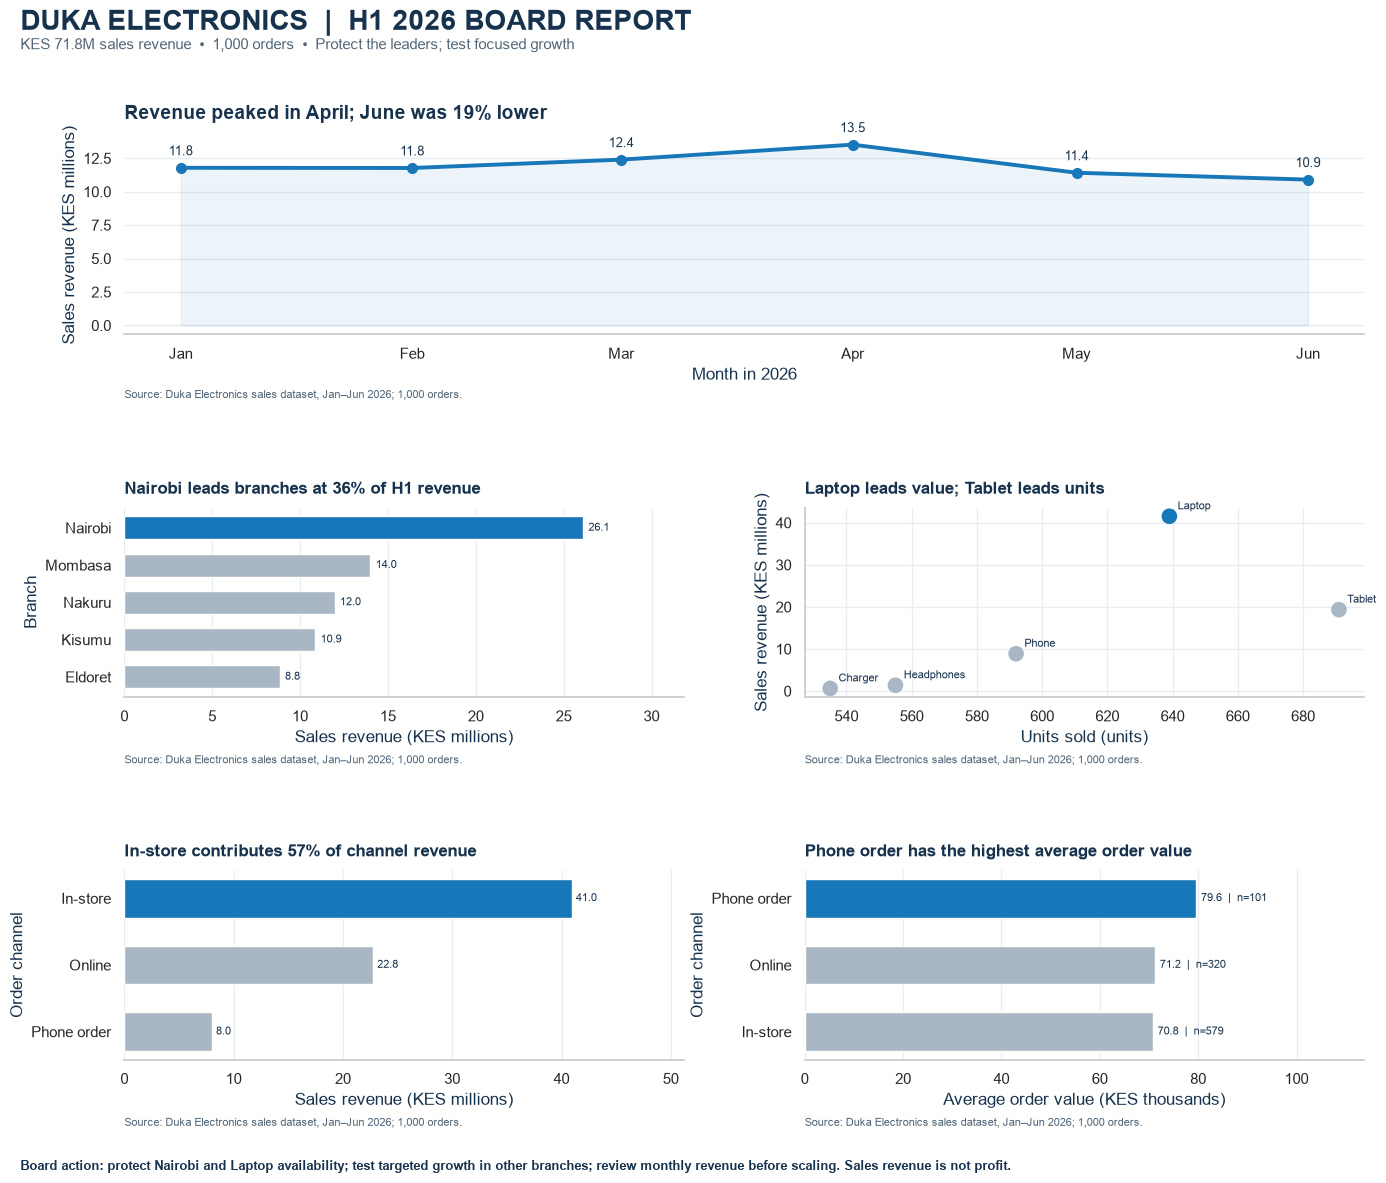

Saved reports/duka_board_report.png and reports/duka_board_report.pdf


In [2]:
sns.set_theme(style='whitegrid', context='notebook')
INK = '#17324D'
BLUE = '#1877B9'
MUTED = '#A9B7C4'
GRID = '#E7EDF2'

fig = plt.figure(figsize=(16, 12), facecolor='white')
grid = fig.add_gridspec(3, 4, height_ratios=[1.05, 1, 1], hspace=0.9, wspace=0.55)
ax_month = fig.add_subplot(grid[0, :])
ax_branch = fig.add_subplot(grid[1, :2])
ax_product = fig.add_subplot(grid[1, 2:])
ax_channel = fig.add_subplot(grid[2, :2])
ax_aov = fig.add_subplot(grid[2, 2:])

peak_month = monthly.idxmax().strftime('%B')
weak_month = monthly.idxmin().strftime('%B')
decline_from_peak = (monthly.max() - monthly.min()) / monthly.max() * 100
ax_month.plot(monthly.index, monthly.values / 1_000_000, color=BLUE, linewidth=2.8, marker='o', markersize=7)
ax_month.fill_between(monthly.index, monthly.values / 1_000_000, color=BLUE, alpha=0.08)
for date, value in monthly.items():
    ax_month.annotate(f'{value / 1_000_000:.1f}', (date, value / 1_000_000), xytext=(0, 9),
                      textcoords='offset points', ha='center', fontsize=9, color=INK)
ax_month.set_title(f"Revenue peaked in {peak_month}; {weak_month} was {decline_from_peak:.0f}% lower",
                   loc='left', color=INK, fontsize=14, fontweight='bold', pad=12)
ax_month.set_ylabel('Sales revenue (KES millions)', color=INK)
ax_month.set_xlabel('Month in 2026', color=INK)
ax_month.set_xticks(monthly.index, monthly.index.strftime('%b'))
ax_month.grid(axis='y', color=GRID)
ax_month.grid(axis='x', visible=False)
ax_month.spines[['top', 'right', 'left']].set_visible(False)
ax_month.text(0, -0.32, source_line, transform=ax_month.transAxes, fontsize=8, color='#536779')

branch_colors = [BLUE] + [MUTED] * (len(branch_revenue) - 1)
bars = ax_branch.barh(branch_revenue.index[::-1], branch_revenue.values[::-1] / 1_000_000,
                      color=branch_colors[::-1], height=0.62)
lead_branch = branch_revenue.index[0]
lead_share = branch_revenue.iloc[0] / branch_revenue.sum() * 100
ax_branch.set_title(f'{lead_branch} leads branches at {lead_share:.0f}% of H1 revenue',
                    loc='left', color=INK, fontsize=12, fontweight='bold', pad=10)
ax_branch.set_xlabel('Sales revenue (KES millions)', color=INK)
ax_branch.set_ylabel('Branch', color=INK)
for bar, value in zip(bars, branch_revenue.values[::-1] / 1_000_000):
    ax_branch.text(value + 0.3, bar.get_y() + bar.get_height()/2, f'{value:.1f}', va='center', fontsize=8, color=INK)
ax_branch.set_xlim(0, branch_revenue.max() / 1_000_000 * 1.22)
ax_branch.grid(axis='x', color=GRID)
ax_branch.grid(axis='y', visible=False)
ax_branch.spines[['top', 'right', 'left']].set_visible(False)
ax_branch.text(0, -0.35, source_line, transform=ax_branch.transAxes, fontsize=8, color='#536779')

top_product = product_summary.index[0]
top_units_product = product_summary['units'].idxmax()
ax_product.scatter(product_summary['units'], product_summary['revenue'] / 1_000_000,
                   s=105, color=[BLUE if p == top_product else MUTED for p in product_summary.index], zorder=3)
for product, row in product_summary.iterrows():
    ax_product.annotate(product, (row['units'], row['revenue']/1_000_000), xytext=(6, 5),
                        textcoords='offset points', fontsize=8, color=INK)
ax_product.set_title(f'{top_product} leads value; {top_units_product} leads units',
                     loc='left', color=INK, fontsize=12, fontweight='bold', pad=10)
ax_product.set_xlabel('Units sold (units)', color=INK)
ax_product.set_ylabel('Sales revenue (KES millions)', color=INK)
ax_product.grid(color=GRID)
ax_product.spines[['top', 'right']].set_visible(False)
ax_product.text(0, -0.35, source_line, transform=ax_product.transAxes, fontsize=8, color='#536779')

channel_by_revenue = channel_summary.sort_values('revenue', ascending=False)
channel_colors = [BLUE] + [MUTED] * (len(channel_by_revenue) - 1)
channel_bars = ax_channel.barh(channel_by_revenue.index[::-1], channel_by_revenue['revenue'].values[::-1] / 1_000_000,
                               color=channel_colors[::-1], height=0.58)
leading_channel = channel_by_revenue.index[0]
leading_channel_share = channel_by_revenue['revenue'].iloc[0] / channel_by_revenue['revenue'].sum() * 100
ax_channel.set_title(f'{leading_channel} contributes {leading_channel_share:.0f}% of channel revenue',
                     loc='left', color=INK, fontsize=12, fontweight='bold', pad=10)
ax_channel.set_xlabel('Sales revenue (KES millions)', color=INK)
ax_channel.set_ylabel('Order channel', color=INK)
for bar, value in zip(channel_bars, channel_by_revenue['revenue'].values[::-1] / 1_000_000):
    ax_channel.text(value + 0.35, bar.get_y() + bar.get_height()/2, f'{value:.1f}', va='center', fontsize=8, color=INK)
ax_channel.set_xlim(0, channel_by_revenue['revenue'].max() / 1_000_000 * 1.25)
ax_channel.grid(axis='x', color=GRID)
ax_channel.grid(axis='y', visible=False)
ax_channel.spines[['top', 'right', 'left']].set_visible(False)
ax_channel.text(0, -0.35, source_line, transform=ax_channel.transAxes, fontsize=8, color='#536779')

channel_by_aov = channel_summary.sort_values('average_order_value', ascending=False)
aov_bars = ax_aov.barh(channel_by_aov.index[::-1], channel_by_aov['average_order_value'].values[::-1] / 1000,
                       color=[BLUE if c == channel_by_aov.index[0] else MUTED for c in channel_by_aov.index[::-1]],
                       height=0.58)
best_aov = channel_by_aov.index[0]
ax_aov.set_title(f'{best_aov} has the highest average order value',
                 loc='left', color=INK, fontsize=12, fontweight='bold', pad=10)
ax_aov.set_xlabel('Average order value (KES thousands)', color=INK)
ax_aov.set_ylabel('Order channel', color=INK)
for bar, (_, row) in zip(aov_bars, channel_by_aov.iloc[::-1].iterrows()):
    ax_aov.text(row['average_order_value']/1000 + 1, bar.get_y() + bar.get_height()/2,
                f"{row['average_order_value']/1000:.1f}  |  n={int(row['orders'])}", va='center', fontsize=8, color=INK)
ax_aov.set_xlim(0, channel_by_aov['average_order_value'].max() / 1000 * 1.43)
ax_aov.grid(axis='x', color=GRID)
ax_aov.grid(axis='y', visible=False)
ax_aov.spines[['top', 'right', 'left']].set_visible(False)
ax_aov.text(0, -0.35, source_line, transform=ax_aov.transAxes, fontsize=8, color='#536779')

fig.suptitle('DUKA ELECTRONICS  |  H1 2026 BOARD REPORT', x=0.06, y=0.985, ha='left',
             fontsize=20, fontweight='bold', color=INK)
fig.text(0.06, 0.952,
         f"KES {sales['revenue'].sum()/1_000_000:.1f}M sales revenue  •  {len(sales):,} orders  •  Protect the leaders; test focused growth",
         ha='left', fontsize=11, color='#536779')
fig.text(0.06, 0.018,
         'Board action: protect Nairobi and Laptop availability; test targeted growth in other branches; review monthly revenue before scaling. Sales revenue is not profit.',
         ha='left', fontsize=9, color=INK, fontweight='bold')

Path('reports').mkdir(exist_ok=True)
fig.savefig('reports/duka_board_report.png', dpi=300, bbox_inches='tight', facecolor='white')
fig.savefig('reports/duka_board_report.pdf', bbox_inches='tight', facecolor='white')
plt.show()
print('Saved reports/duka_board_report.png and reports/duka_board_report.pdf')

## Chart makeover — branch revenue

The before version uses unsorted bars, default category colours, an uninformative title, raw KES values, and unnecessary gridlines. The after version sorts branches by revenue, uses one highlight colour for Nairobi, labels values in KES millions, calculates the title from the leading branch's revenue share, clarifies the unit, removes nonessential borders/gridlines, and adds the source. Both plots use the same underlying branch totals.

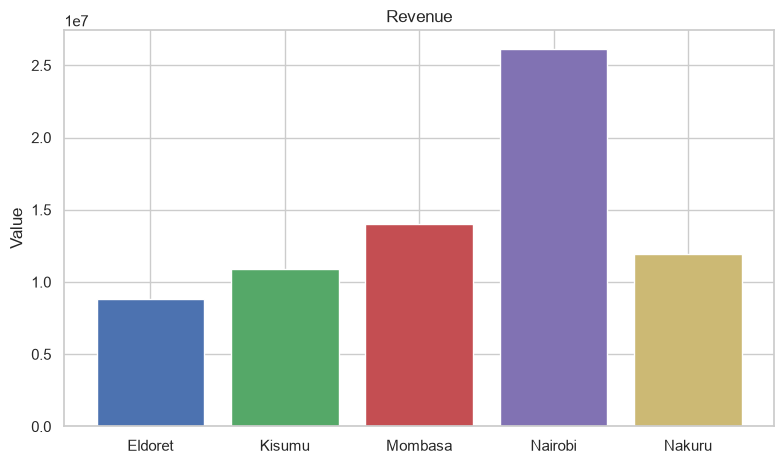

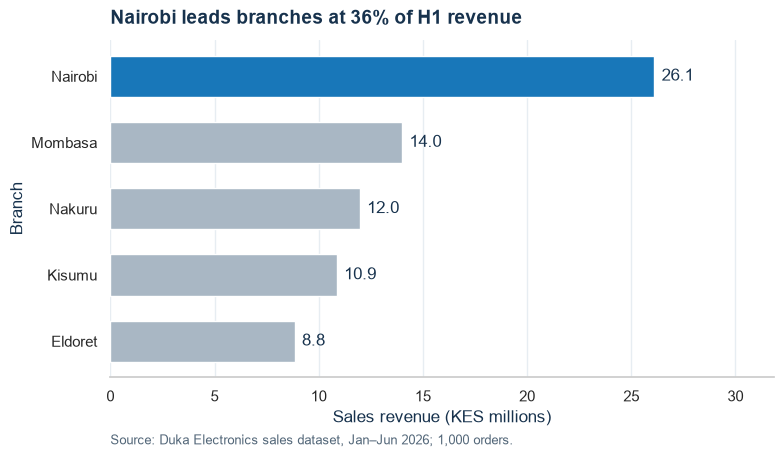

Saved figures/before.png and figures/after.png


In [3]:
Path('figures').mkdir(exist_ok=True)
before_order = sales.groupby('branch')['revenue'].sum()
fig_before, ax = plt.subplots(figsize=(8, 4.8))
ax.bar(before_order.index, before_order.values, color=['#4C72B0', '#55A868', '#C44E52', '#8172B3', '#CCB974'])
ax.set_title('Revenue')
ax.set_ylabel('Value')
ax.grid(True)
fig_before.tight_layout()
fig_before.savefig('figures/before.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

ordered = before_order.sort_values()
fig_after, ax = plt.subplots(figsize=(8, 4.8))
colors = [BLUE if branch == ordered.index[-1] else MUTED for branch in ordered.index]
bars = ax.barh(ordered.index, ordered.values / 1_000_000, color=colors, height=0.62)
share = ordered.iloc[-1] / ordered.sum() * 100
ax.set_title(f'{ordered.index[-1]} leads branches at {share:.0f}% of H1 revenue',
             loc='left', color=INK, fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Sales revenue (KES millions)', color=INK)
ax.set_ylabel('Branch', color=INK)
for bar, value in zip(bars, ordered.values / 1_000_000):
    ax.text(value + 0.35, bar.get_y() + bar.get_height()/2, f'{value:.1f}', va='center', color=INK)
ax.set_xlim(0, ordered.max() / 1_000_000 * 1.22)
ax.grid(axis='x', color=GRID)
ax.grid(axis='y', visible=False)
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.text(0, -0.2, source_line, transform=ax.transAxes, fontsize=9, color='#536779')
fig_after.tight_layout()
fig_after.savefig('figures/after.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved figures/before.png and figures/after.png')

## Board recommendation and caveats

1. **Protect the revenue leaders:** maintain Laptop availability and a strong customer experience in Nairobi, the largest branch by sales value.
2. **Test, then scale:** run measurable demand-building pilots in lower-revenue branches and review monthly sales against the H1 baseline.
3. **Investigate the April–June movement:** identify operational or customer drivers before committing resources to a recovery plan.

The dataset records sales revenue, not gross margin or profit, and has no stock, promotion, or customer data. It supports prioritizing tests, not claiming why branches or months performed differently. Review the dashboard brief in `dashboard.md` for the interactive version.